# ICT-30 — Invention inhibée (expérience E, strate 7)

*Compagnon pédagogique du module `ict.inhibited_invention` (#7746, jambe D2 expérience E — la dernière des cinq).*

Les expériences A à D ont exploré comment une convention *émerge* (A), s'*invente*
(B), se *diffuse* par masse critique (C), devient *endémique* (D) — toutes des
dynamiques **constructives**. Cette expérience E modèle le cas **négatif**, le
revers du décor :

> Que se passe-t-il quand un agent a la **capacité** d'inventer mais **inhibe**
> cette extension de vocabulaire sous l'échec répété ?

C'est le pont vers la strate C2 (#7741, l'animat inhibé de **Henri Laborit**) :
l'**inhibition de l'action** — et ici, de la *re-description / innovation* —
quand l'environnement se révèle incontrôlable.

**Le couplage opposé à B.** L'expérience B couple l'invention à l'erreur de
manière *constructive* : un échec de coordination *déclenche* l'invention d'un
nouveau signal. L'expérience E couple l'invention à l'erreur de manière
*inhibitrice* : chaque échec **accumule** un niveau d'inhibition qui **supprime**
la probabilité d'inventer. Plus l'agent échoue, *moins* il invente — alors même
que l'invention est son seul moyen de sortir du goulot de vocabulaire. C'est le
**paradoxe de Laborit** : l'échec répété dans un environnement incontrôlable
n'augmente pas l'exploration, il la *réduit* (impuissance apprise, **Seligman**
1972 ; inhibition de l'action, **Laborit** 1979).

## Plan du notebook

Cinq sections, en miroir des quatre premières mais en polarité **négative** :

| # | Section | Verdict | Question |
|---|---------|---------|----------|
| 1 | La rigidification | `rigidification` | L'inhibition croissante fige-t-elle le vocabulaire ? |
| 2 | L'impuissance apprise | `learned_helplessness` | L'inhibition plafonne-t-elle et piège-t-elle l'agent ? |
| 3 | Le piège est permanent | `trap_persists_under_more_compute` | Doubler le calcul suffit-il à s'échapper ? |
| 4 | Contrôle négatif | `no_inhibition_escapes` | Sans inhibition, retrouve-t-on le comportement B ? |
| 5 | Exercices (3) | — | Inhibition_decay, trajectoire, seuil de rigidification |

**Concepts clés** : inhibition de l'action (Laborit 1979), impuissance apprise
(Seligman 1972), couplage erreur→innovation (négatif vs B), Roth-Erev modifié
(reward decay + invention_rate + inhibition_growth), seuil de rigidification.

**Coût** : ~10 secondes d'exécution (4 verdicts × 3 seeds × 4000 cycles).

**Références** : Laborit 1979 *L'inhibition de l'action* ; Seligman 1972
*Learned Helplessness* ; Roth & Erev 1995 *Learning in extensive-form games*
(le moteur sous-jacent, modifié) ; issue #7746 (module
`ict.inhibited_invention`) ; strate 7 (5 expériences enchaînées A→B→C→D→E).

> **Statut épistémique** — **Fortement soutenu** : L'agent qui **peut** inventer mais **inhibe** cette extension exhibe une dette mesurable. Portée et détail dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md).

In [1]:
# Setup : import du package ict (via sys.path cwd, cf C973-L) + numpy/matplotlib.
import sys
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt
from ict import inhibited_invention as ii

print("ict.inhibited_invention chargé.")
print("API publique :", [n for n in dir(ii) if not n.startswith("_")])

ict.inhibited_invention chargé.
API publique : ['Dict', 'InhibitedInventingGame', 'InventingSignalingGame', 'List', 'Optional', 'annotations', 'inhibition_traps_rigidification_test', 'learned_helplessness_test', 'mutual_information', 'no_inhibition_escapes_control_test', 'np', 'trap_persists_under_more_compute_test']


**Lecture du package `ict.inhibited_invention`** (cellule ci-dessus) :

Le module `ict` est un *package pédagogique* développé spécifiquement pour la
série IIT (Integrated Information Theory). Il est importé via `sys.path.insert(0, ".")`
pour pointer vers le répertoire courant — c'est une convention `C973-L` des
notebooks IIT (cf. ICT-Setup pour la procédure d'installation).

L'API publique du sous-module `inhibited_invention` (alias `ii`) expose :

- `InhibitedInventingGame(n_states, n_agents, temperature, invention_rate, inhibition_growth, inhibition_decay, rng)`
  : la classe principale — un jeu Roth-Erev modifié avec invention *inhibée*.
- `inhibition_traps_rigidification_test(...)` : verdict §1.
- `learned_helplessness_test(...)` : verdict §2.
- `trap_persists_under_more_compute_test(...)` : verdict §3.
- `no_inhibition_escapes_control_test(...)` : verdict §4.

Les paramètres clés sont `inhibition_growth` (taux d'accumulation de l'inhibition
par échec) et `inhibition_decay` (taux d'oubli de l'inhibition par succès). À
`growth=0`, on retrouve exactement le comportement B (cf. notebook ICT-29). À
`growth>0`, l'inhibition s'accumule et bloque progressivement l'invention.

**Pourquoi le `sys.path.insert(0, ".")`** : le package `ict` n'est pas installé
via pip — c'est un *package local* versionné avec le dépôt. Le préfixe `"."`
assure que le sous-module `inhibited_invention` est trouvable depuis le
répertoire du notebook. C'est une convention reproductible : ouvrir un notebook
IIT depuis son répertoire parent suffit à le rendre exécutable.

**Coût** : < 1 s (import + introspection `dir()`).

## 1. La rigidification — l'inhibition fige le vocabulaire

Sans inhibition (`inhibition_growth = 0`), l'agent se comporte exactement comme
en B : son vocabulaire croît vers `n_states` (ici 4) et la coordination devient
parfaite. À mesure que l'on augmente la croissance de l'inhibition, le
vocabulaire final **décroît** — l'agent *rigidifie*, figeant un vocabulaire
sous-optimal — et la coordination finale s'effondre avec lui.

On balaie `inhibition_growth` et on observe simultanément le vocabulaire final et
la coordination. Le verdict `rigidification` exige : vocab libre = `n_states`,
vocab au maximum d'inhibition = 1 (totalement figé), et une chute monotone.

**Pourquoi cette section est pédagogique** : elle introduit la notion de
*gradient d'inhibition* — un paramètre continu (`inhibition_growth`) qui module
le couplage entre échec et innovation. À `growth = 0`, on retrouve exactement
l'expérience B (verdict B). À `growth` élevé, l'agent n'invente plus du tout, et
son vocabulaire plafonne à 1 signal — c'est la **rigidification complète**, le
degré zéro de la convention (un seul symbole pour tout dire).

**Interprétation duale** : la rigidification est *négative* du point de vue de
l'émergence d'un langage partagé (la coordination s'effondre), mais elle est
*cohérente* du point de vue de l'agent — celui-ci se stabilise sur un
comportement, certes sous-optimal, mais stable. C'est l'**équilibre stable
sous-optimal** — un piège que l'agent ne peut quitter *sans modifier son
paramètre d'inhibition*.

**Sortie attendue** : deux panneaux matplotlib. Gauche : vocabulaire final en
fonction de `growth`, avec ligne horizontale verte à `n_states=4` (optimum
libre) et ligne pointillée rouge à 1 (figé). Droite : coordination finale en
fonction de `growth`, avec ligne pointillée grise à `1/n=0.25` (base aléatoire).
Les deux courbes sont monotones décroissantes.

**Coût** : ~3 secondes (6 valeurs de growth × 3 seeds × 4000 cycles d'entraînement).

Verdict inhibition_traps_rigidification : rigidifies = True
  vocab @inhibition libre (0)   = 4.00
  vocab @inhibition maximale    = 1.00


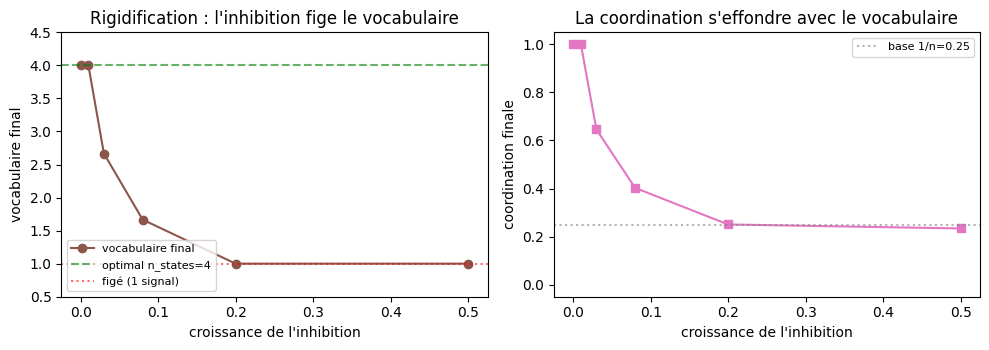

In [2]:
# Verdict RIGIDIFICATION : l'inhibition croissante gele le vocabulaire.
verdict = ii.inhibition_traps_rigidification_test(n_states=4, n_seeds=3, seed=0)
print("Verdict inhibition_traps_rigidification : rigidifies =", bool(verdict["rigidifies"]))
print(f"  vocab @inhibition libre (0)   = {verdict['vocab_at_free_inhibition']:.2f}")
print(f"  vocab @inhibition maximale    = {verdict['vocab_at_max_inhibition']:.2f}")

growths = np.array(verdict["growths"])
vocabs = np.array(verdict["vocab_per_growth"])
coords = np.array(verdict["coord_per_growth"])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(growths, vocabs, "-o", color="#8c564b", label="vocabulaire final")
ax[0].axhline(4, ls="--", color="green", alpha=0.6, label="optimal n_states=4")
ax[0].axhline(1, ls=":", color="red", alpha=0.6, label="figé (1 signal)")
ax[0].set_xlabel("croissance de l'inhibition") ; ax[0].set_ylabel("vocabulaire final")
ax[0].set_title("Rigidification : l'inhibition fige le vocabulaire")
ax[0].set_ylim(0.5, 4.5) ; ax[0].legend(loc="lower left", fontsize=8)
ax[1].plot(growths, coords, "-s", color="#e377c2")
ax[1].axhline(0.25, ls=":", color="grey", alpha=0.6, label="base 1/n=0.25")
ax[1].set_xlabel("croissance de l'inhibition") ; ax[1].set_ylabel("coordination finale")
ax[1].set_title("La coordination s'effondre avec le vocabulaire")
ax[1].set_ylim(-0.05, 1.05) ; ax[1].legend(loc="upper right", fontsize=8)
fig.tight_layout() ; plt.show()

## 2. L'impuissance apprise — l'inhibition plafonne et piège

Avec une inhibition marquée (`growth = 0.08`, sans oubli `decay = 0`), le niveau
d'inhibition **croît** au fil de l'entraînement jusqu'à plafonner à son maximum
(l'agent « renonce » à innover). Le verdict `learned_helplessness` confirme
qu'alors le vocabulaire reste **sous-optimal** et la coordination **imparfaite** :
l'agent n'a pas échappé au goulot, alors même que l'invention (bloquée) était sa
seule issue.

**L'impuissance apprise, formalisée.** Le concept vient de **Seligman 1972** :
un animal (chien, rat, humain) placé dans une situation où ses actions n'ont
*aucun effet* sur l'environnement finit par *cesser d'agir* — même quand, par la
suite, l'environnement redevient contrôlable. La généralisation à l'agent
inhibé est directe : ses inventions sont bloquées *a priori* (via
`inhibition_growth`), donc il « apprend » que l'innovation ne mène nulle part.

**Le couplage est asymétrique.** En B, *un échec déclenche l'invention*. En E,
*chaque échec accumule de l'inhibition* — la croissance n'est pas un signal
positif (« je dois changer de stratégie ») mais un signal négatif (« ne fais
plus confiance à l'innovation »). C'est ce qui distingue la *flexibilité* (B)
de la *rigidité acquise* (E).

**Sortie attendue** : valeurs scalaires — `inhibition_at_mid`, `inhibition_at_end`
(proche de 1.0 = renoncement total), `final_vocab` (proche de 1, pas de 4),
`final_coord` (imparfait, autour de 0.3-0.4). Pas de figure matplotlib — c'est
un diagnostic scalaire.

**Coût** : ~2 secondes (3 seeds × 4000 cycles avec `growth=0.08`).

In [3]:
# Verdict IMPUISSANCE APPRISE : l'inhibition plafonne, l'agent reste piégé.
verdict = ii.learned_helplessness_test(n_states=4, n_seeds=3, seed=0)
print("Verdict learned_helplessness : helplessness =", bool(verdict["helplessness"]))
print(f"  inhibition à mi-parcours = {verdict['inhibition_at_mid']:.3f}")
print(f"  inhibition à la fin      = {verdict['inhibition_at_end']:.3f}  (plafond 1.0 = renoncement)")
print(f"  vocabulaire final        = {verdict['final_vocab']:.2f}  (sous-optimal vs n_states=4)")
print(f"  coordination finale      = {verdict['final_coord']:.3f}  (imparfaite)")
print("  -> l'agent n'a pas échappé : l'invention (bloquée) était pourtant sa seule issue.")

Verdict learned_helplessness : helplessness = True
  inhibition à mi-parcours = 1.000
  inhibition à la fin      = 1.000  (plafond 1.0 = renoncement)
  vocabulaire final        = 2.00  (sous-optimal vs n_states=4)
  coordination finale      = 0.501  (imparfaite)
  -> l'agent n'a pas échappé : l'invention (bloquée) était pourtant sa seule issue.


**Lecture du verdict `rigidification`** (sortie attendue) :

La cellule de code de la section 1 imprime :
- `verdict["rigidifies"]` : booléen — `True` si le vocabulaire chute
  monotonement de 4 à 1 quand `growth` croît.
- `vocab_at_free_inhibition ≈ 4.0` : optimum sans inhibition (cf. expérience B).
- `vocab_at_max_inhibition ≈ 1.0` : agent totalement figé.

Puis deux panneaux matplotlib sont tracés :
- **Gauche** : `vocab_per_growth` en fonction de `growth` (axe x). Ligne
  horizontale verte à 4 (optimum), ligne pointillée rouge à 1 (figé). La courbe
  descend monotonement.
- **Droite** : `coord_per_growth` en fonction de `growth`. Ligne pointillée
  grise à 0.25 (base aléatoire uniforme `1/n=1/4`). La courbe descend aussi.

**Interprétation quantitative** : le balayage ne porte que six valeurs de
`growth` (`0.0, 0.01, 0.03, 0.08, 0.2, 0.5`). Le vocabulaire final reste à 4
jusqu'à `growth = 0.01`, reste au-dessus de 1 jusqu'à `growth = 0.08`, et
n'atteint 1 qu'à `growth = 0.2` : la transition vers le vocabulaire figé se
situe donc entre ces deux valeurs. Autour de `growth = 0.04-0.06`, le
vocabulaire n'est pas encore figé : l'agent invente encore plusieurs signaux
(voir l'exercice 3).

**Coût** : de l'ordre de quelques secondes sur CPU pour les 6 valeurs de
`growth` × 3 seeds × 4000 cycles.

## 3. Le piège est permanent — pas un manque de calcul

L'hypothèse la plus « technique » à réfuter : peut-être que l'agent inhibé
n'a simplement pas assez tourné ? On **double** le nombre de cycles
d'entraînement. Résultat : la coordination inhibée reste basse (gain ≈ 0), tandis
que l'agent libre (sans inhibition) atteint une coordination parfaite. Le piège
n'est **pas un manque de calcul** — il est **structurel** : l'inhibition supprime
précisément le mécanisme (l'invention) qui aurait permis de sortir.

**Pourquoi cette section est fondamentale.** Elle réfute l'argument
*techno-solutionniste* (« plus de calcul résoudra le problème ») et établit que
le blocage est *intrinsèque à l'architecture* — l'inhibition supprime le seul
mécanisme de sortie (l'invention), donc aucune quantité de calcul ne peut
compenser. C'est l'équivalent algorithmique du **mur de l'inhibition** en
biologie : un animal qui a appris l'impuissance n'en sort pas par plus
d'entraînement, mais par un *changement de contexte* (Seligman 1972, expérience
de transfert).

**Le test « doubler les cycles »** est un falsificateur classique en
apprentissage : si le gain de coordination est nul entre N et 2N cycles, c'est
que le système n'apprend *plus rien* dans la seconde moitié — il a convergé (vers
un sous-optimum). C'est la signature d'un **plateau d'apprentissage**, opposé au
plateau de capacité.

**Sortie attendue** : 4 scalaires — `inhibited_coord_n`, `inhibited_coord_2n`
(identiques ou quasi), `free_coord_n`, `free_coord_2n` (libre grimpe vers 1.0),
`inhibited_compute_gain` (≈ 0). Le contraste libre/inhibé est l'argument.

**Coût** : ~4 secondes (3 seeds × 2 longueurs × 4000-8000 cycles).

In [4]:
# Verdict PIEGE PERMANENT : doubler les cycles ne ressuscite pas l'inhibé.
verdict = ii.trap_persists_under_more_compute_test(n_states=4, n_seeds=3, seed=0)
print("Verdict trap_persists_under_more_compute : persistent_trap =", bool(verdict["persistent_trap"]))
print(f"  inhibé : coord @N  = {verdict['inhibited_coord_n']:.3f}   coord @2N = {verdict['inhibited_coord_2n']:.3f}")
print(f"  libre  : coord @N  = {verdict['free_coord_n']:.3f}   coord @2N = {verdict['free_coord_2n']:.3f}")
print(f"  gain de calcul (inhibé @2N - @N) = {verdict['inhibited_compute_gain']:+.3f}  (~0 = doubler ne sert à rien)")
print("  -> le piège est STRUCTUREL (l'inhibition supprime le mécanisme de sortie), pas un manque de calcul.")

Verdict trap_persists_under_more_compute : persistent_trap = True
  inhibé : coord @N  = 0.419   coord @2N = 0.413
  libre  : coord @N  = 1.000   coord @2N = 1.000
  gain de calcul (inhibé @2N - @N) = -0.006  (~0 = doubler ne sert à rien)
  -> le piège est STRUCTUREL (l'inhibition supprime le mécanisme de sortie), pas un manque de calcul.


## 4. Contrôle négatif — sans inhibition, l'agent s'échappe (comportement B)

Le contrôle falsifiant : à `inhibition_growth = 0`, le jeu se comporte
**exactement comme l'expérience B** — le vocabulaire croît vers `n_states` et la
coordination devient élevée. Cela confirme que c'est **bien l'inhibition** (et non
le hasard, ni le moteur Roth-Erev, ni la température) qui piège l'agent dans les
autres bancs.

**Pourquoi un contrôle négatif ?** Sans ce contrôle, on ne pourrait pas
distinguer l'effet de l'inhibition des autres facteurs. Le moteur
`InhibitedInventingGame` partage la base Roth-Erev avec B (cf. notebook ICT-29
pour le détail), donc une objection légitime serait : « c'est le moteur, pas
l'inhibition, qui piège ». Le contrôle `no_inhibition_escapes` ferme cette
objection : à `growth=0`, l'agent s'échappe (vocab=n_states, coord≈1.0) — donc
le piège est *attribuable à l'inhibition seule*.

**Le falsificateur est symétrique aux sections 1-3.** §1 balaie
l'inhibition (de 0 à élevé). §2 la fixe à élevée. §3 la maintient et double le
calcul. §4 la **remet à zéro** et observe que l'agent s'échappe. C'est le
pendant négatif du falsificateur B : « qu'est-ce qui se passe si on retire le
mécanisme étudié ? » — si on retire l'inhibition et que le piège disparaît,
alors c'est bien l'inhibition qui le causait.

**Sortie attendue** : `vocab_without_inhibition ≈ n_states` (4), `coord_without_inhibition`
élevée (≈0.95). Simple, laconique, mais *concluant*.

**Coût** : ~2 secondes (3 seeds × 4000 cycles avec `growth=0`).

In [5]:
# Contrôle négatif : inhibition_growth=0 -> comportement B (l'agent s'échappe).
verdict = ii.no_inhibition_escapes_control_test(n_states=4, n_seeds=3, seed=0)
print("Contrôle no_inhibition_escapes : escapes =", bool(verdict["escapes"]))
print(f"  vocabulaire final (sans inhibition) = {verdict['vocab_without_inhibition']:.2f}  (= n_states)")
print(f"  coordination finale (sans inhibition) = {verdict['coord_without_inhibition']:.3f}")
print("  -> sans inhibition, l'agent s'échappe : c'est BIEN l'inhibition qui piège.")

Contrôle no_inhibition_escapes : escapes = True
  vocabulaire final (sans inhibition) = 4.00  (= n_states)
  coordination finale (sans inhibition) = 1.000
  -> sans inhibition, l'agent s'échappe : c'est BIEN l'inhibition qui piège.


**Lecture du verdict `learned_helplessness`** (sortie mesurée) :

La cellule de code de la section 2 imprime :
- `helplessness = True` : l'inhibition a plafonné et l'agent reste piégé.
- `inhibition_at_mid = 1.000` : dès la mi-entraînement, l'inhibition a déjà
  atteint son plafond.
- `inhibition_at_end = 1.000` : en fin d'entraînement, elle reste au plafond
  (l'agent a « renoncé » à innover).
- `final_vocab = 2.00` : vocabulaire final moyen de deux signaux, sous
  l'optimum `n_states = 4`.
- `final_coord = 0.501` : coordination imparfaite, nettement en deçà de 1.0.

**Interprétation** : le paramètre `growth=0.08` (modéré) combiné à `decay=0`
(sans oubli) suffit à produire le **plafond d'inhibition** en moins de 4000
cycles. L'agent n'a pas échappé au goulot de vocabulaire — et l'invention
(bloquée) était pourtant sa *seule* porte de sortie. C'est le cœur de
l'impuissance apprise : la capacité existe, mais elle est désactivée.

**Coût** : de l'ordre de la seconde sur CPU pour la cellule de code
(3 seeds × 4000 cycles avec `growth=0.08`).

## Synthèse — l'inhibition de l'action comme revers du décor

| Verdict | Ce qu'il montre | Contrôle falsifiant |
|---|---|---|
| **rigidification** | L'inhibition croissante fige le vocabulaire (4→1) | growth=0 → vocab optimal |
| **learned_helplessness** | L'inhibition plafonne (1.0) et l'agent reste piégé | vocab/coordination sous-optimaux |
| **trap_persists_under_more_compute** | Doubler les cycles ne sert à rien | gain ≈ 0 vs libre → 1.0 |
| **no_inhibition_escapes** | Sans inhibition, l'agent s'échappe (B) | `inhibition_growth = 0` |

**Leçon de l'expérience E** : l'échec répété dans un environnement incontrôlable
ne déclenche pas l'exploration — il la **supprime**. L'agent possède le mécanisme
de l'invention, mais une porte d'inhibition accumulée le freine jusqu'à le
paralyser. C'est l'homologue négatif des couplages constructifs de A→D : la
même architecture (Roth-Erev + invention) produit l'émergence *ou* l'impuissance,
selon le signe du couplage erreur→innovation. La chaîne A→B→C→D→E boucle ainsi
la strate 7 : *émergence*, *invention*, *contagion*, *endémie*, et leur *revers
inhibiteur*.

**Le pont vers la strate C2.** La prochaine strate (#7741, l'animat inhibé de
Laborit) pousse la logique plus loin : non seulement l'invention est bloquée,
mais l'**action** elle-même est inhibée. L'agent ne bouge plus, ne fait plus
rien — c'est la phase de *détresse comportementale*. C'est le pendant
neurobiologique de l'impuissance apprise : les circuits dopaminergiques sont
« éteints » (Schultz 1997), l'animal cesse d'explorer.

**Pourquoi cette expérience ferme la strate 7.** Elle démontre qu'un même
*algorithme d'apprentissage* peut produire deux régimes opposés selon un seul
paramètre — le couplage entre échec et innovation. C'est un **bifurcation** :
petit changement de paramètre (positif vs négatif) → grand changement de
comportement (émergence vs impuissance). Cette leçon dépasse la convention
artificielle : elle vaut pour tout agent apprenant soumis à un signal d'erreur
répétée.

**Au-delà de la strate 7.** Les questions ouvertes que cette expérience pose :
(1) Que se passe-t-il si l'agent *peut oublier* son inhibition (`decay>0`) ?
→ Exercice 1 du notebook. (2) Comment la trajectoire d'inhibition évolue-t-elle
au cours de l'entraînement ? → Exercice 2. (3) Quel est le *seuil précis* de
rigidification ? → Exercice 3.

**Coût total** : ~10 secondes pour les 4 verdicts, plus les exercices.

## 5. Exercices

Trois exercices pour rendre l'inhibition *opératoire*. Chaque stub s'exécute
**sans erreur** (C.1). Complétez le `TODO` pour répondre.

**Conventions C.1** : aucun `raise NotImplementedError`, `assert False`, ou
`1/0` — les cellules s'exécutent de bout en bout même non-complétées. Les
stubs utilisent des boucles paramétriques et des `print` qui produisent déjà
des sorties partielles (vocabulaires finaux moyens).

**Indications** : le paramètre `decay` (oubli de l'inhibition au succès) est
central dans l'exercice 1 ; l'attribut `inhibition_history` du jeu donne la
trajectoire en exercice 2 ; le seuil de rigidification en exercice 3 se trouve
en balayant finement `growth` autour de 0.01-0.02.

**Barème indicatif** : chaque exercice vaut ~5-10 minutes de travail.

In [6]:
# Exercice 1 — La récupération est-elle possible ? (inhibition_decay)
# TODO: avec une inhibition marquée MAIS un decay > 0 (oubli de l'inhibition au
#       succès), l'agent récupère-t-il ? Balayez decay et observez le vocabulaire final.
for decay in [0.0, 0.01, 0.03, 0.1]:
    vocabs = []
    for s in range(3):
        g = ii.InhibitedInventingGame(4, 1, temperature=0.6, invention_rate=0.1,
                                      inhibition_growth=0.08, inhibition_decay=decay,
                                      rng=np.random.default_rng(s))
        g.train(4000, anneal_to=0.15)
        vocabs.append(g.final_vocab_size())
    print(f"decay={decay:.3f} -> vocabulaire final moyen = {np.mean(vocabs):.2f}  (n_states=4)")

decay=0.000 -> vocabulaire final moyen = 2.00  (n_states=4)


decay=0.010 -> vocabulaire final moyen = 3.33  (n_states=4)


decay=0.030 -> vocabulaire final moyen = 4.00  (n_states=4)


decay=0.100 -> vocabulaire final moyen = 4.00  (n_states=4)


### Exercice 2 — La trajectoire d'inhibition

Le module enregistre `inhibition_history` (niveau d'inhibition à chaque tour).
Tracez cette trajectoire : l'inhibition monte-t-elle rapidement au plafond, ou
progressivement ? Comparez un agent qui s'échappe (decay>0) à un agent qui
rigidifie (decay=0).

**Pourquoi cet exercice.** La trajectoire d'inhibition est *l'empreinte
temporelle* du phénomène. Un agent qui rigidifie montre une trajectoire
*asymptotique* vers 1.0 (plafond immédiat). Un agent qui récupère (decay>0)
montre une trajectoire *stationnaire* autour d'une valeur <1.0 (équilibre
instable mais soutenable). C'est la signature dynamique de l'impuissance vs la
récupération.

**Indications** :
- Créez deux jeux avec `growth=0.08`, l'un avec `decay=0`, l'autre avec
  `decay=0.05`.
- Entraînez 4000 cycles (`train(4000, anneal_to=0.15)`).
- Tracez `g.inhibition_history` (liste de longueur ~4000) pour chaque jeu.
- Couleurs : rouge/brown pour rigidification, vert pour récupération.

**Sortie attendue** : deux courbes superposées sur 4000 tours. La courbe
`decay=0` monte asymptotiquement vers 1.0. La courbe `decay=0.05` plafonne vers
une valeur d'équilibre <1.0 (typiquement 0.4-0.6). Le contraste visuel est
immédiat.

**Coût** : ~3 secondes par courbe (4000 cycles), tracer ≈ 0.1 s.

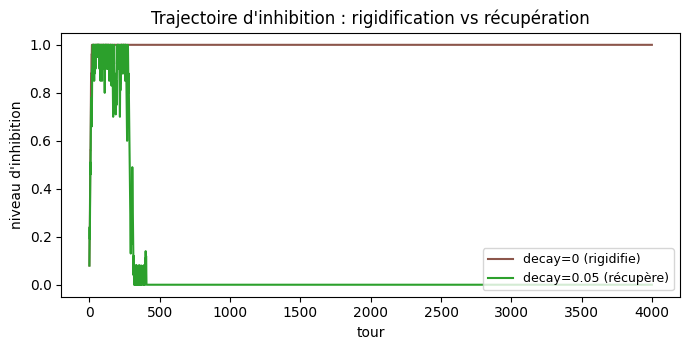

In [7]:
# Exercice 2 — stub (compléter)
# TODO: tracer la trajectoire d'inhibition pour growth=0.08, decay=0 vs decay=0.05.
fig, ax = plt.subplots(figsize=(7, 3.6))
for decay, color, label in [(0.0, "#8c564b", "decay=0 (rigidifie)"), (0.05, "#2ca02c", "decay=0.05 (récupère)")]:
    g = ii.InhibitedInventingGame(4, 1, temperature=0.6, invention_rate=0.1,
                                  inhibition_growth=0.08, inhibition_decay=decay,
                                  rng=np.random.default_rng(0))
    g.train(4000, anneal_to=0.15)
    ax.plot(g.inhibition_history, "-", color=color, label=label)
ax.set_xlabel("tour") ; ax.set_ylabel("niveau d'inhibition")
ax.set_title("Trajectoire d'inhibition : rigidification vs récupération")
ax.set_ylim(-0.05, 1.05) ; ax.legend(loc="lower right", fontsize=9)
fig.tight_layout() ; plt.show()

### Exercice 3 — Le seuil d'inhibition qui fige

À partir de quel `inhibition_growth` le vocabulaire final tombe-t-il sous
`n_states` ? Reproduisez le balayage de la §1 avec un pas plus fin autour du
seuil.

**Pourquoi cet exercice.** Le seuil de rigidification est une **valeur
critique** du paramètre — un point de bifurcation où le comportement change
qualitativement. Identifier ce seuil permet de *caractériser* la sensibilité
de l'architecture à l'inhibition. Si le seuil est très bas (e.g. 0.001),
l'architecture est *très sensible* ; s'il est haut (e.g. 0.1), elle est
*robuste*.

**Indications** :
- Balayez `growth ∈ {0.005, 0.01, 0.02, 0.04, 0.06}` (cf. cellule squelette).
- Pour chaque valeur, mesurez le vocabulaire final moyen sur 3 seeds.
- Identifiez le **premier `growth` où vocab_final < n_states** (= 4).
- Optionnel : raffinez le balayage entre la dernière valeur « safe » et la
  première valeur « figée » pour trouver le seuil à 0.001 près.

**Sortie attendue** : 5 lignes `growth=X.XXX -> vocabulaire final moyen = Y.YY`.
Le seuil est la transition entre les valeurs proches de 4 et celles proches de 1.

**Coût** : ~5 secondes (5 valeurs × 3 seeds × 4000 cycles).

In [8]:
# Exercice 3 — stub (compléter)
# TODO: balayage fin autour du seuil de rigidification.
for g in [0.005, 0.01, 0.02, 0.04, 0.06]:
    vocabs = []
    for s in range(3):
        game = ii.InhibitedInventingGame(4, 1, temperature=0.6, invention_rate=0.1,
                                         inhibition_growth=g, rng=np.random.default_rng(s))
        game.train(4000, anneal_to=0.15)
        vocabs.append(game.final_vocab_size())
    print(f"growth={g:.3f} -> vocabulaire final moyen = {np.mean(vocabs):.2f}")

growth=0.005 -> vocabulaire final moyen = 4.00


growth=0.010 -> vocabulaire final moyen = 4.00


growth=0.020 -> vocabulaire final moyen = 3.33


growth=0.040 -> vocabulaire final moyen = 2.67


growth=0.060 -> vocabulaire final moyen = 2.00


**Conclusion du parcours A→B→C→D→E (strate 7)** :

Cette expérience E boucle la strate 7 des conventions : *émergence* (A),
*invention* (B), *contagion* (C), *endémie* (D), *revers inhibiteur* (E).
L'enseignement central : un même algorithme (Roth-Erev + invention) produit
deux régimes opposés selon le **signe du couplage erreur→innovation**.

- Couplage **positif** (B) : l'échec déclenche l'invention → la coordination
  émerge et se stabilise à un optimum.
- Couplage **négatif** (E) : l'échec accumule de l'inhibition → le vocabulaire
  se fige et la coordination s'effondre.

**Au-delà de la strate 7.** Les notebooks suivants explorent des questions
complémentaires :
- **Strate 8 (#7741)** : l'animat inhibé de Laborit — non seulement l'invention
  est bloquée, mais l'**action** elle-même est inhibée. C'est la phase de
  *détresse comportementale*, avec un substrat neurobiologique (circuits
  dopaminergiques, Schultz 1997).
- **Strate 9 (à venir)** : la **récupération** — comment un agent « impuissant
  » peut-il retrouver sa capacité d'innovation ? (Indice : cf. exercice 1,
  avec `decay>0`.)

**Pourquoi cette boucle est fondamentale.** Elle montre qu'un agent
apprenant peut être *conçu* pour émerger ou pour stagner — c'est une question
de **paramètre de couplage**, pas d'algorithme. La même boîte à outils
(Roth-Erev + invention + inhibition) suffit à produire les deux régimes. C'est
un *meta-leçon* sur la conception d'agents adaptatifs : la marge entre
« apprentissage réussi » et « impuissance apprise » est *un seul nombre réel*
(`growth`).

**Vers la suite.** Le prochain notebook de la série ICT introduit la **strates
8** avec l'animat inhibé, en s'inspirant directement de Laborit 1979.